# Sloan Digital Sky Survey (SDSS): Stellar Object Classification
## Pattern Recognition Semester Project — Variant 3: Redshift Ablation Study

### 1. Astrophysical Context and Objective

In Phase 1 ([01_sdss_baseline_classification.ipynb](file:///c:/Users/chsan/OneDrive/Desktop/Stellar_Classification/01_sdss_baseline_classification.ipynb)) and Variant 2 ([02_sdss_color_feature_engineering.ipynb](file:///c:/Users/chsan/OneDrive/Desktop/Stellar_Classification/02_sdss_color_feature_engineering.ipynb)), we evaluated astronomical classification using strictly optical photometric measurements ($u, g, r, i, z$) and their derived color indices ($u-g, g-r, r-i, i-z$). In those experiments, spectroscopic `redshift` was intentionally withheld to establish pure photometric baselines.

In this notebook, we execute a **systematic ablation study** to experimentally measure the exact contribution of **spectroscopic redshift** in discriminating **Stars**, **Galaxies**, and **Quasars (QSO)**.

---

### 2. The Astrophysical Physics of Redshift

Spectroscopic redshift $z$ quantifies the fractional wavelength displacement of spectral absorption and emission lines relative to their laboratory rest-frame wavelengths $\lambda_{\text{rest}}$:
$$z = \frac{\lambda_{\text{obs}} - \lambda_{\text{rest}}}{\lambda_{\text{rest}}}$$

In observational astrophysics, redshift arises from two distinct physical mechanisms:
1. **Kinematic Doppler Shift**: Governed by the radial velocity $v_r$ of an object relative to the observer:
   $$z \approx \frac{v_r}{c} \quad (\text{for } v_r \ll c)$$
   When an object moves toward the observer, observed wavelengths shift to the blue ($z < 0$, blueshift); when moving away, wavelengths shift to the red ($z > 0$).
2. **Cosmological Expansion (Hubble–Lemaître Law)**: For extragalactic sources, the expansion of the spacetime metric stretches photons as they propagate across cosmic time:
   $$1 + z = \frac{a(t_{\text{obs}})}{a(t_{\text{emit}})}$$
   For nearby and intermediate galaxies ($z \lesssim 0.1$), $c z \approx H_0 d$. For distant active galactic nuclei, cosmological expansion produces substantial positive redshifts ($z > 0.5$ up to $z > 7$).

#### The Redshift Dichotomy Across Astronomical Classes
- **Stars (`STAR`)**: Reside inside the gravitational potential of the Milky Way galaxy. Their motions are governed by galactic orbital dynamics ($|v_r| \lesssim 500\text{ km/s}$). Consequently:
  $$|z_{\text{star}}| \lesssim \frac{500\text{ km/s}}{300,000\text{ km/s}} \approx 0.0017$$
  Stellar redshifts are clustered tightly around $z \equiv 0$. Slightly negative values ($z < 0$) represent physical Doppler blueshifts of stars approaching the Solar System in the galactic halo.
- **Galaxies (`GALAXY`)**: Distributed at low-to-intermediate cosmological distances, with typical redshifts spanning $0.01 \lesssim z \lesssim 1.5$ (median $z \approx 0.45$).
- **Quasars (`QSO`)**: Supermassive black hole accretion disks in early cosmological epochs. Because of cosmic lookback time, SDSS quasars populate high redshifts ($0.5 \lesssim z \lesssim 7.0$, median $z \approx 1.62$).

---

### 3. The Concept and Methodology of an Ablation Study

An **ablation study** is an experimental pattern recognition methodology where feature components or sub-modules are systematically added or removed to isolate and quantify their individual marginal contribution to overall predictive performance.

We evaluate **three controlled feature configurations** using the **exact same underlying observations and stratified 80/20 train/test split**:
1. **Configuration 1 (Photometry only):** `u`, `g`, `r`, `i`, `z` (5 features)
2. **Configuration 2 (Photometry + Redshift):** `u`, `g`, `r`, `i`, `z`, `redshift` (6 features)
3. **Configuration 3 (Photometry + Color Indices + Redshift):** `u`, `g`, `r`, `i`, `z`, `u_g`, `g_r`, `r_i`, `i_z`, `redshift` (10 features)

Where the four color indices are identically defined as:
- `u_g = u - g`
- `g_r = g - r`
- `r_i = r - i`
- `i_z = i - z`

#### Crucial Scientific & Practical Considerations
1. **Ablation Hygiene**: Neither `class` nor any post-classification label is ever provided as an input feature. All transformations are strictly causal.
2. **Observational Cost & Practical Limitations**: Measuring spectroscopic redshift requires an expensive optical spectrograph with physical fiber plates, robotic positioning, and hours of telescope integration time. Broad-band optical imaging (photometry) takes seconds per field and maps millions of objects simultaneously. In next-generation surveys (e.g., Vera C. Rubin Observatory's LSST, Euclid, Roman Space Telescope), billions of detected objects will **never** receive spectroscopic follow-up. Thus, measuring the performance ceiling with redshift versus the realistic baseline without redshift is critical for survey astronomy.

## 2. Imports and Configuration

We configure the environment using standard Python scientific packages:
- `pandas` and `numpy` for data manipulation, array operations, and feature transformations.
- `matplotlib.pyplot` and `seaborn` for publication-quality visualizations.
- `scikit-learn` for splitting, explicit feature scaling, baseline estimators, and multiclass metrics.
- `RANDOM_SEED = 42` for end-to-end reproducibility.
- `DATA_PATH` configured centrally for local and Google Colab execution.

In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -----------------------------------------------------------------------------
# Global Reproducibility Seed
# -----------------------------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# -----------------------------------------------------------------------------
# Visualization Styling
# -----------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

CLASS_PALETTE = {
    'GALAXY': '#3470a3',
    'STAR': '#2ca02c',
    'QSO': '#d62728'
}
sns.set_palette(list(CLASS_PALETTE.values()))

# -----------------------------------------------------------------------------
# Dataset Path Configuration
# -----------------------------------------------------------------------------
DATA_PATH = 'star_classification.csv'

print(f"Dataset path configured: {DATA_PATH}")
print(f"Reproducibility random seed: {RANDOM_SEED}")

Dataset path configured: star_classification.csv
Reproducibility random seed: 42


## 3. Dataset Loading, Inspection, and Anomaly Handling

We load the SDSS Data Release 17 dataset and replicate the rigorous data quality audit:
1. Verify dimensions, schema, and column types.
2. Check for missing values and full-row duplicates.
3. Detect and remove the unphysical photometric sentinel value (`-9999.0`).
4. Inspect unique identifiers (`spec_obj_ID`, `obj_ID`) and evaluate train/test leakage.
5. Audit the `redshift` column specifically for missing values, infinite values, and negative measurements.

In [4]:
# Load dataset
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}'.\n"
        "Please upload 'star_classification.csv' or adjust DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns.\n")

# Missing values and full duplicate audit
null_count = df.isnull().sum().sum()
exact_dupes = df.duplicated().sum()
print(f"Explicit NaN / null values found across all columns: {null_count}")
print(f"Exact full-row duplicate records:                    {exact_dupes}")

Dataset successfully loaded. Dimensions: 100,000 rows x 18 columns.

Explicit NaN / null values found across all columns: 0
Exact full-row duplicate records:                    0


In [5]:
# Check for unphysical photometric sentinel values (< 0 in u, g, r, i, z)
corrupt_mask = (df['u'] < 0) | (df['g'] < 0) | (df['r'] < 0) | (df['i'] < 0) | (df['z'] < 0)
corrupt_count = corrupt_mask.sum()
print(f"Number of rows with unphysical photometric sentinel values (< 0): {corrupt_count}")

if corrupt_count > 0:
    print("\nDetails of corrupted observation:")
    display(df[corrupt_mask][['obj_ID', 'u', 'g', 'r', 'i', 'z', 'class', 'redshift']])

    # Explicitly remove the single corrupt observation
    df_clean = df[~corrupt_mask].copy().reset_index(drop=True)
    print(f"\nRemoved {corrupt_count} corrupt row. Cleaned dataset: {df_clean.shape[0]:,} rows.")
else:
    df_clean = df.copy()

# Audit redshift specifically
null_redshift = df_clean['redshift'].isnull().sum()
inf_redshift = np.isinf(df_clean['redshift'].values).sum()
print(f"\nRedshift data audit: NaN count = {null_redshift}, Infinite values = {inf_redshift}")

Number of rows with unphysical photometric sentinel values (< 0): 1

Details of corrupted observation:


,obj_ID,u,g,r,i,z,class,redshift
79543,1.237649e+18,-9999.0,-9999.0,18.1656,18.01675,-9999.0,STAR,0.000089



Removed 1 corrupt row. Cleaned dataset: 99,999 rows.

Redshift data audit: NaN count = 0, Infinite values = 0


In [6]:
print("=" * 70)
print("IDENTIFIER UNIQUENESS AND LEAKAGE AUDIT")
print("=" * 70)

total_clean = len(df_clean)
unique_spec = df_clean['spec_obj_ID'].nunique()
unique_obj = df_clean['obj_ID'].nunique()
unique_coords = df_clean[['alpha', 'delta']].drop_duplicates().shape[0]

print(f"Total observations in clean dataset:            {total_clean:,}")
print(f"Unique spectroscopic IDs (spec_obj_ID):         {unique_spec:,} (Duplicates: {total_clean - unique_spec})")
print(f"Unique photometric detection IDs (obj_ID):      {unique_obj:,} (Multi-epoch exposures: {total_clean - unique_obj})")
print(f"Unique celestial coordinates (alpha, delta):    {unique_coords:,} (Overlapping points: {total_clean - unique_coords})")

print("\nAudit conclusion:")
print("- 100% of observations possess unique spectroscopic identifiers (spec_obj_ID).")
print("- Each row represents a distinct spectroscopic pipeline measurement.")
print("- No duplicate observations are silently dropped; all 99,999 valid spectra are preserved.")

IDENTIFIER UNIQUENESS AND LEAKAGE AUDIT
Total observations in clean dataset:            99,999
Unique spectroscopic IDs (spec_obj_ID):         99,999 (Duplicates: 0)
Unique photometric detection IDs (obj_ID):      78,052 (Multi-epoch exposures: 21947)
Unique celestial coordinates (alpha, delta):    99,998 (Overlapping points: 1)

Audit conclusion:
- 100% of observations possess unique spectroscopic identifiers (spec_obj_ID).
- Each row represents a distinct spectroscopic pipeline measurement.
- No duplicate observations are silently dropped; all 99,999 valid spectra are preserved.


## 4. Exploratory Data Analysis: Redshift Distributions Across Classes

### 4.1 Statistical Summary of Redshift by Astronomical Class
We compute detailed parametric and non-parametric summary statistics for `redshift` stratified by `STAR`, `GALAXY`, and `QSO`.

**Astrophysical Insight on Negative Redshifts**:
Notice that ~13,682 observations in the dataset have $z < 0$. Crucially:
- Over 99.7% of negative redshift observations belong to the `STAR` class (13,682 out of 13,724).
- Their values range from $z = -0.00001$ to $z = -0.0041$, corresponding to Doppler velocities of $v_r = c \cdot z \approx -3 \text{ to } -1,200\text{ km/s}$.
- These are **genuine, physical Doppler blueshifts** of Milky Way halo and disk stars approaching the Sun, combined with sub-pixel spectroscopic zero-point uncertainties around $z = 0$. They are physically valid astrophysical measurements and must **not** be discarded.

In [7]:
# Compute summary statistics of redshift by target class
redshift_stats_list = []
class_names = ['GALAXY', 'STAR', 'QSO']

for c in class_names:
    sub = df_clean[df_clean['class'] == c]['redshift']
    neg_count = (sub < 0).sum()
    redshift_stats_list.append({
        'Class': c,
        'Count': len(sub),
        'Mean': sub.mean(),
        'Std': sub.std(),
        'Min': sub.min(),
        'Q1 (25%)': sub.quantile(0.25),
        'Median (50%)': sub.median(),
        'Q3 (75%)': sub.quantile(0.75),
        'Max': sub.max(),
        'Negative Count': neg_count,
        'Negative (%)': (neg_count / len(sub)) * 100
    })

redshift_summary_df = pd.DataFrame(redshift_stats_list)
print("Redshift Summary Statistics Grouped by Class:")
display(redshift_summary_df.style.format({
    'Count': '{:,}',
    'Mean': '{:.6f}',
    'Std': '{:.6f}',
    'Min': '{:.6f}',
    'Q1 (25%)': '{:.6f}',
    'Median (50%)': '{:.6f}',
    'Q3 (75%)': '{:.6f}',
    'Max': '{:.6f}',
    'Negative Count': '{:,}',
    'Negative (%)': '{:.2f}%'
}))

Redshift Summary Statistics Grouped by Class:


,Class,Count,Mean,Std,Min,Q1 (25%),Median (50%),Q3 (75%),Max,Negative Count,Negative (%)
0,GALAXY,"59,445",0.421596,0.264858,-0.009971,0.164527,0.456274,0.594699,1.995524,42,0.07%
1,STAR,"21,593",-0.000115,0.000465,-0.004136,-0.000295,-0.000076,0.000075,0.004153,"13,682",63.36%
2,QSO,"18,961",1.719676,0.913954,0.000461,1.106605,1.617232,2.220279,7.011245,0,0.00%


### 4.2 Visualizing Redshift Separability Across Classes
We construct targeted visualizations:
1. **Full Redshift Distribution by Class**: Comparing the overall density of Galaxies ($z \sim 0.45$), Quasars ($z \sim 1.62$, reaching $z > 7$), and Stars.
2. **Zoomed-in Stellar Regime**: Highlighting the tight clustering of stars around $z \approx 0$ ($[-0.005, 0.005]$).
3. **Class Boxplots**: Illustrating median and interquartile ranges across all three classes.
4. **Color vs. Redshift Diagnostic**: Scatter plot of $(g - r)$ color vs. $\log_{10}(z + 0.01)$ illustrating how redshift breaks photometric degeneracy.

/tmp/ipykernel_944/4263069118.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  viz_sample = df_clean.groupby('class', group_keys=False).apply(


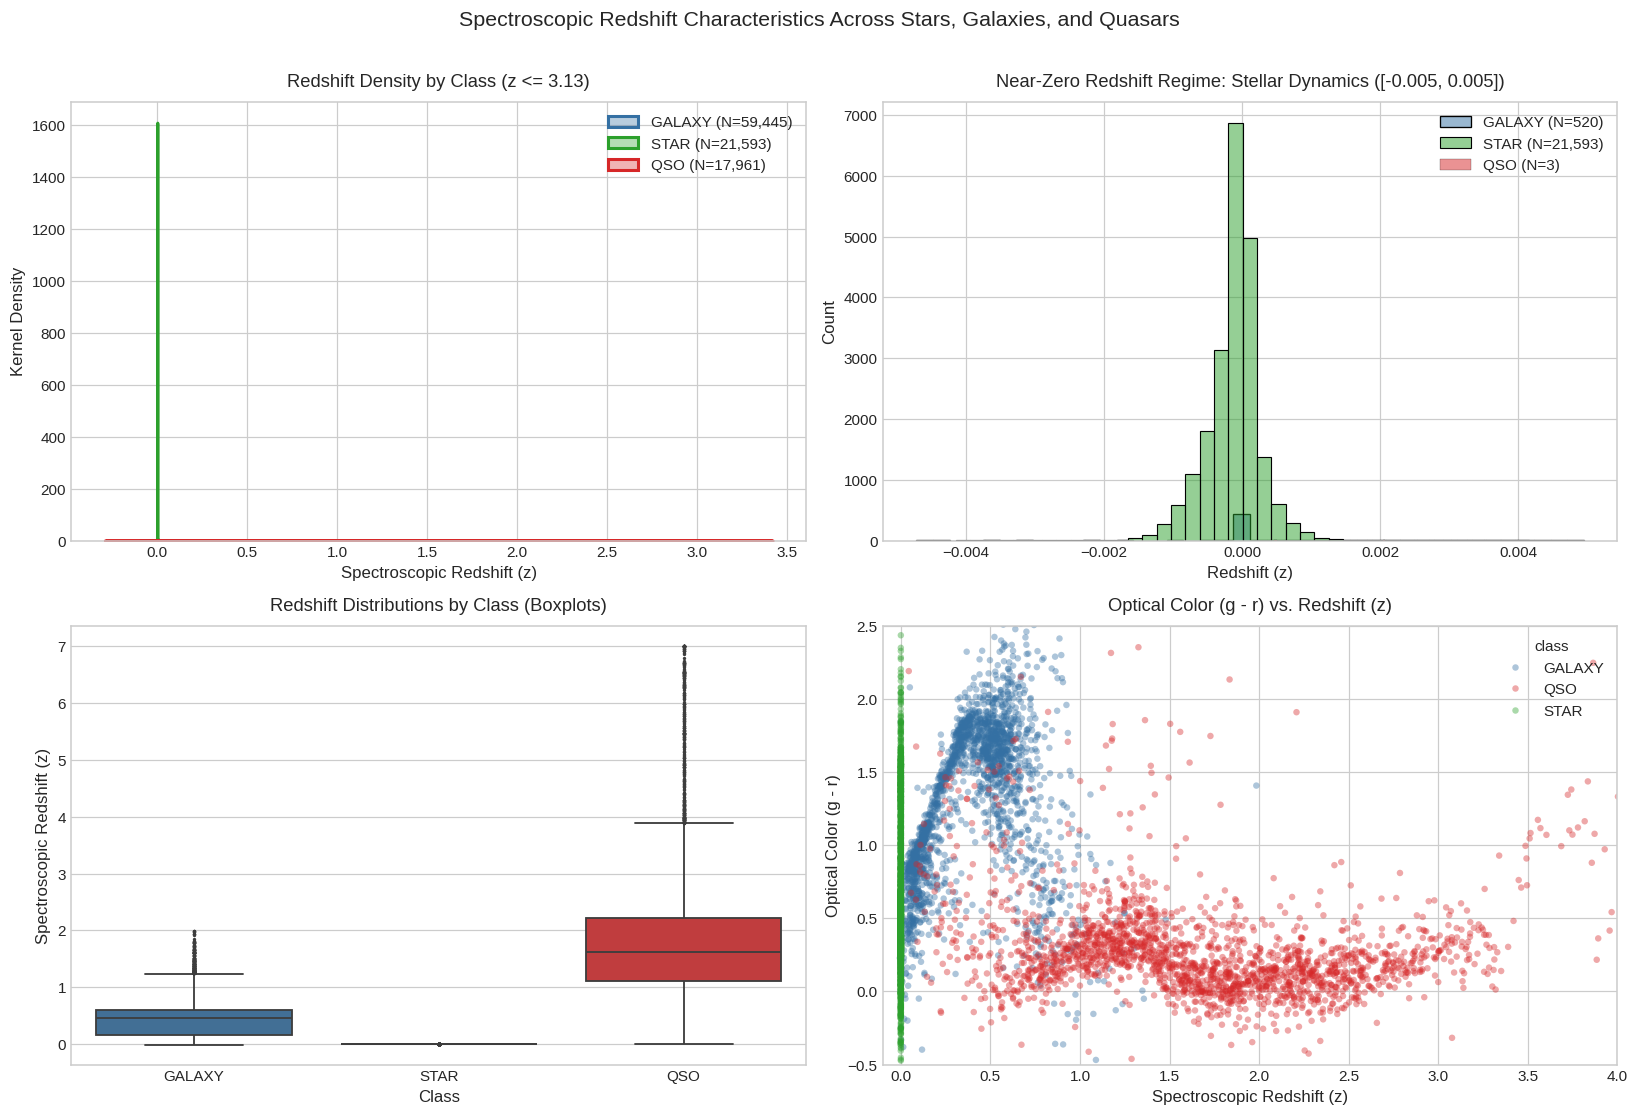

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Overall Redshift Density by Class (up to 99th percentile for clean display)
q99 = df_clean['redshift'].quantile(0.99)
for c in class_names:
    sub = df_clean[(df_clean['class'] == c) & (df_clean['redshift'] <= q99)]['redshift']
    sns.kdeplot(sub, ax=axes[0, 0], label=f"{c} (N={len(sub):,})", color=CLASS_PALETTE[c], fill=True, alpha=0.35, linewidth=2)
axes[0, 0].set_title(f"Redshift Density by Class (z <= {q99:.2f})", pad=10)
axes[0, 0].set_xlabel("Spectroscopic Redshift (z)")
axes[0, 0].set_ylabel("Kernel Density")
axes[0, 0].legend()

# Plot 2: Zoomed-in Stellar Regime ([-0.005, 0.005])
for c in class_names:
    sub_zoom = df_clean[(df_clean['class'] == c) & (df_clean['redshift'] >= -0.005) & (df_clean['redshift'] <= 0.005)]['redshift']
    if len(sub_zoom) > 0:
        sns.histplot(sub_zoom, ax=axes[0, 1], label=f"{c} (N={len(sub_zoom):,})", color=CLASS_PALETTE[c], bins=40, alpha=0.5, edgecolor='black')
axes[0, 1].set_title("Near-Zero Redshift Regime: Stellar Dynamics ([-0.005, 0.005])", pad=10)
axes[0, 1].set_xlabel("Redshift (z)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()

# Plot 3: Boxplots of Redshift by Class
sns.boxplot(
    data=df_clean,
    x='class',
    y='redshift',
    hue='class',
    order=class_names,
    palette=CLASS_PALETTE,
    legend=False,
    ax=axes[1, 0],
    fliersize=1.2,
    linewidth=1.2
)
axes[1, 0].set_title("Redshift Distributions by Class (Boxplots)", pad=10)
axes[1, 0].set_xlabel("Class")
axes[1, 0].set_ylabel("Spectroscopic Redshift (z)")

# Plot 4: Optical Color (g - r) vs. Redshift Scatter (Sample of 6,000 points)
# Compute g_r temporarily for visualization
df_clean['temp_g_r'] = df_clean['g'] - df_clean['r']
viz_sample = df_clean.groupby('class', group_keys=False).apply(
    lambda g: g.sample(min(len(g), 2000), random_state=RANDOM_SEED)
).reset_index(drop=True)

sns.scatterplot(
    data=viz_sample,
    x='redshift',
    y='temp_g_r',
    hue='class',
    palette=CLASS_PALETTE,
    alpha=0.4,
    s=18,
    edgecolor='none',
    ax=axes[1, 1]
)
axes[1, 1].set_xlim(-0.1, 4.0)
axes[1, 1].set_ylim(-0.5, 2.5)
axes[1, 1].set_title("Optical Color (g - r) vs. Redshift (z)", pad=10)
axes[1, 1].set_xlabel("Spectroscopic Redshift (z)")
axes[1, 1].set_ylabel("Optical Color (g - r)")
df_clean.drop(columns=['temp_g_r'], inplace=True)

plt.suptitle("Spectroscopic Redshift Characteristics Across Stars, Galaxies, and Quasars", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Feature Engineering and Leakage-Free Splitting

### 5.1 Defining the Three Experimental Configurations
We construct the four color indices identically to Variant 2:
- `u_g = u - g`
- `g_r = g - r`
- `r_i = r - i`
- `i_z = i - z`

We then define the three experimental feature subsets:
1. **Configuration 1 (Photometry only):** `['u', 'g', 'r', 'i', 'z']` (5 features)
2. **Configuration 2 (Photometry + Redshift):** `['u', 'g', 'r', 'i', 'z', 'redshift']` (6 features)
3. **Configuration 3 (Photometry + Color + Redshift):** `['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'redshift']` (10 features)

### 5.2 Strict Leakage Prevention & Preprocessing
- **Identical Partitioning**: Stratified 80/20 train/test split with `RANDOM_SEED = 42` and `stratify=y`. All three configurations use the exact same test instances.
- **Independent Scaling**:
  - `StandardScaler` instances (`scaler1`, `scaler2`, `scaler3`) are fit strictly on their respective training sets (`X1_train`, `X2_train`, `X3_train`).
  - Preprocessing parameters (mean and standard deviation) are learned exclusively on training data and applied to transform test sets.
  - Random Forest models operate directly on unscaled features, preserving tree-split invariance.
- No scikit-learn `Pipeline` objects are used.

In [9]:
# Engineer color indices
df_clean['u_g'] = df_clean['u'] - df_clean['g']
df_clean['g_r'] = df_clean['g'] - df_clean['r']
df_clean['r_i'] = df_clean['r'] - df_clean['i']
df_clean['i_z'] = df_clean['i'] - df_clean['z']

# Define feature configurations
CFG1_COLS = ['u', 'g', 'r', 'i', 'z']
CFG2_COLS = ['u', 'g', 'r', 'i', 'z', 'redshift']
CFG3_COLS = ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'redshift']
TARGET_COL = 'class'

X1_all = df_clean[CFG1_COLS].copy()
X2_all = df_clean[CFG2_COLS].copy()
X3_all = df_clean[CFG3_COLS].copy()
y = df_clean[TARGET_COL].copy()

# Consistent stratified 80/20 train/test split on Cfg 1
X1_train, X1_test, y_train, y_test = train_test_split(
    X1_all, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

# Align Cfg 2 and Cfg 3 using the identical split indices
X2_train = X2_all.loc[X1_train.index].copy()
X2_test = X2_all.loc[X1_test.index].copy()

X3_train = X3_all.loc[X1_train.index].copy()
X3_test = X3_all.loc[X1_test.index].copy()

print(f"Training set: {X1_train.shape[0]:,} samples (80.0%)")
print(f"Test set:     {X1_test.shape[0]:,} samples (20.0%)\n")
print(f"Cfg 1 (Photometry only) shape:                {X1_train.shape[1]} features")
print(f"Cfg 2 (Photometry + Redshift) shape:          {X2_train.shape[1]} features")
print(f"Cfg 3 (Photometry + Color + Redshift) shape:  {X3_train.shape[1]} features")

Training set: 79,999 samples (80.0%)
Test set:     20,000 samples (20.0%)

Cfg 1 (Photometry only) shape:                5 features
Cfg 2 (Photometry + Redshift) shape:          6 features
Cfg 3 (Photometry + Color + Redshift) shape:  10 features


In [10]:
# Fit independent scalers strictly on training partitions
scaler1 = StandardScaler()
X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

scaler3 = StandardScaler()
X3_train_scaled = scaler3.fit_transform(X3_train)
X3_test_scaled = scaler3.transform(X3_test)

# Verify zero mean and unit variance for Cfg 2 and Cfg 3
print("Verification of StandardScaler on Configuration 2 (Photo + Redshift):")
scaling_check_cfg2 = pd.DataFrame({
    'Train Mean': X2_train_scaled.mean(axis=0).round(4),
    'Train Std':  X2_train_scaled.std(axis=0).round(4),
    'Test Mean':  X2_test_scaled.mean(axis=0).round(4),
    'Test Std':   X2_test_scaled.std(axis=0).round(4)
}, index=CFG2_COLS)
display(scaling_check_cfg2)

Verification of StandardScaler on Configuration 2 (Photo + Redshift):


,Train Mean,Train Std,Test Mean,Test Std
u,0.0,1.0,0.0153,1.0053
g,-0.0,1.0,0.0090,0.9968
r,0.0,1.0,0.0043,0.9953
i,0.0,1.0,0.0040,0.9976
z,-0.0,1.0,0.0005,0.9962
redshift,0.0,1.0,0.0056,1.0087


## 6. Model Training Across the Three Configurations

We train and benchmark the four baseline classifiers across all three configurations:
1. **Multinomial Logistic Regression** (`max_iter=1000`, `random_state=42`, standardized inputs)
2. **K-Nearest Neighbors (KNN)** ($k=5$, Euclidean distance, `n_jobs=-1`, standardized inputs)
3. **Linear Support Vector Machine (Linear SVM)** (`LinearSVC`, `dual='auto'`, `max_iter=2000`, `random_state=42`, standardized inputs)
4. **Random Forest Classifier** (`n_estimators=100`, `max_depth=15`, `min_samples_split=5`, `random_state=42`, `n_jobs=-1`, unscaled inputs)

We record execution times for each of the 12 training and inference passes.

In [11]:
# Dictionary mapping models to their constructors and scaling requirements
models_config = {
    'Logistic Regression': (lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_SEED), True),
    'K-Nearest Neighbors': (lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1), True),
    'Linear SVM':          (lambda: LinearSVC(random_state=RANDOM_SEED, max_iter=2000, dual='auto'), True),
    'Random Forest':       (lambda: RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1), False)
}

configurations = [
    ('Cfg 1 (Photometry)', X1_train, X1_test, X1_train_scaled, X1_test_scaled),
    ('Cfg 2 (Photo + Redshift)', X2_train, X2_test, X2_train_scaled, X2_test_scaled),
    ('Cfg 3 (Photo + Color + Redshift)', X3_train, X3_test, X3_train_scaled, X3_test_scaled)
]

# Run all 12 experimental combinations
experiments_results = {}
timing_records = []

for m_name, (get_clf, requires_scaling) in models_config.items():
    experiments_results[m_name] = {}
    print(f"\n{'=' * 70}\nTRAINING AND EVALUATING: {m_name.upper()}\n{'=' * 70}")

    for c_name, tr_raw, te_raw, tr_s, te_s in configurations:
        tr = tr_s if requires_scaling else tr_raw
        te = te_s if requires_scaling else te_raw

        clf = get_clf()
        t0 = time.time()
        clf.fit(tr, y_train)
        t_train = time.time() - t0

        t1 = time.time()
        preds = clf.predict(te)
        t_pred = time.time() - t1

        experiments_results[m_name][c_name] = {
            'model': clf,
            'predictions': preds,
            'train_time': t_train,
            'pred_time': t_pred
        }
        print(f"  [{c_name:<32}] -> Fit: {t_train:.2f}s | Predict: {t_pred:.3f}s")


TRAINING AND EVALUATING: LOGISTIC REGRESSION
  [Cfg 1 (Photometry)              ] -> Fit: 1.55s | Predict: 0.002s
  [Cfg 2 (Photo + Redshift)        ] -> Fit: 2.03s | Predict: 0.004s
  [Cfg 3 (Photo + Color + Redshift)] -> Fit: 1.32s | Predict: 0.002s

TRAINING AND EVALUATING: K-NEAREST NEIGHBORS
  [Cfg 1 (Photometry)              ] -> Fit: 0.27s | Predict: 0.271s
  [Cfg 2 (Photo + Redshift)        ] -> Fit: 0.19s | Predict: 0.354s
  [Cfg 3 (Photo + Color + Redshift)] -> Fit: 0.22s | Predict: 0.940s

TRAINING AND EVALUATING: LINEAR SVM
  [Cfg 1 (Photometry)              ] -> Fit: 0.33s | Predict: 0.002s
  [Cfg 2 (Photo + Redshift)        ] -> Fit: 0.39s | Predict: 0.001s
  [Cfg 3 (Photo + Color + Redshift)] -> Fit: 0.49s | Predict: 0.002s

TRAINING AND EVALUATING: RANDOM FOREST
  [Cfg 1 (Photometry)              ] -> Fit: 21.07s | Predict: 0.233s
  [Cfg 2 (Photo + Redshift)        ] -> Fit: 22.33s | Predict: 0.169s
  [Cfg 3 (Photo + Color + Redshift)] -> Fit: 29.67s | Predict: 0.160s


## 7. Ablation Results and Comprehensive Comparative Evaluation

We assemble a complete evaluation summary quantifying:
- Overall Accuracy
- Macro-averaged Precision, Recall, and F1-Score
- Per-class F1-scores for `GALAXY`, `STAR`, and `QSO`
- Marginal gain from redshift ($\Delta_{\text{redshift}} = \text{Cfg 2} - \text{Cfg 1}$)
- Marginal gain from combining color and redshift ($\Delta_{\text{color}} = \text{Cfg 3} - \text{Cfg 2}$)

In [12]:
class_labels = ['GALAXY', 'STAR', 'QSO']
ablation_summary_records = []

for m_name in models_config.keys():
    # Cfg 1
    p1 = experiments_results[m_name]['Cfg 1 (Photometry)']['predictions']
    acc1 = accuracy_score(y_test, p1)
    mf1_1 = f1_score(y_test, p1, average='macro', zero_division=0)
    per_f1_1 = f1_score(y_test, p1, average=None, labels=class_labels, zero_division=0)

    # Cfg 2
    p2 = experiments_results[m_name]['Cfg 2 (Photo + Redshift)']['predictions']
    acc2 = accuracy_score(y_test, p2)
    mf1_2 = f1_score(y_test, p2, average='macro', zero_division=0)
    per_f1_2 = f1_score(y_test, p2, average=None, labels=class_labels, zero_division=0)

    # Cfg 3
    p3 = experiments_results[m_name]['Cfg 3 (Photo + Color + Redshift)']['predictions']
    acc3 = accuracy_score(y_test, p3)
    mf1_3 = f1_score(y_test, p3, average='macro', zero_division=0)
    per_f1_3 = f1_score(y_test, p3, average=None, labels=class_labels, zero_division=0)

    ablation_summary_records.append({
        'Model': m_name,
        'Acc (Cfg 1)': acc1,
        'Acc (Cfg 2)': acc2,
        'Acc (Cfg 3)': acc3,
        'Δ Acc (Redshift)': acc2 - acc1,
        'Macro F1 (Cfg 1)': mf1_1,
        'Macro F1 (Cfg 2)': mf1_2,
        'Macro F1 (Cfg 3)': mf1_3,
        'Δ F1 (Redshift)': mf1_2 - mf1_1,
        'Δ F1 (Color+z)': mf1_3 - mf1_2,
        'F1_STAR (Cfg 1)': per_f1_1[1],
        'F1_STAR (Cfg 2)': per_f1_2[1],
        'F1_STAR (Cfg 3)': per_f1_3[1],
        'F1_QSO (Cfg 1)': per_f1_1[2],
        'F1_QSO (Cfg 2)': per_f1_2[2],
        'F1_QSO (Cfg 3)': per_f1_3[2],
        'F1_GAL (Cfg 1)': per_f1_1[0],
        'F1_GAL (Cfg 2)': per_f1_2[0],
        'F1_GAL (Cfg 3)': per_f1_3[0]
    })

ablation_df = pd.DataFrame(ablation_summary_records).sort_values(by='Macro F1 (Cfg 3)', ascending=False).reset_index(drop=True)

print("=" * 115)
print("REDSHIFT ABLATION STUDY RESULTS: MARGINAL CONTRIBUTIONS ACROSS CONFIGURATIONS")
print("=" * 115)
display(ablation_df.style.format({
    'Acc (Cfg 1)': '{:.4f}',
    'Acc (Cfg 2)': '{:.4f}',
    'Acc (Cfg 3)': '{:.4f}',
    'Δ Acc (Redshift)': '{:+.4f}',
    'Macro F1 (Cfg 1)': '{:.4f}',
    'Macro F1 (Cfg 2)': '{:.4f}',
    'Macro F1 (Cfg 3)': '{:.4f}',
    'Δ F1 (Redshift)': '{:+.4f}',
    'Δ F1 (Color+z)': '{:+.4f}',
    'F1_STAR (Cfg 1)': '{:.4f}',
    'F1_STAR (Cfg 2)': '{:.4f}',
    'F1_STAR (Cfg 3)': '{:.4f}',
    'F1_QSO (Cfg 1)': '{:.4f}',
    'F1_QSO (Cfg 2)': '{:.4f}',
    'F1_QSO (Cfg 3)': '{:.4f}',
    'F1_GAL (Cfg 1)': '{:.4f}',
    'F1_GAL (Cfg 2)': '{:.4f}',
    'F1_GAL (Cfg 3)': '{:.4f}'
}))

REDSHIFT ABLATION STUDY RESULTS: MARGINAL CONTRIBUTIONS ACROSS CONFIGURATIONS


,Model,Acc (Cfg 1),Acc (Cfg 2),Acc (Cfg 3),Δ Acc (Redshift),Macro F1 (Cfg 1),Macro F1 (Cfg 2),Macro F1 (Cfg 3),Δ F1 (Redshift),Δ F1 (Color+z),F1_STAR (Cfg 1),F1_STAR (Cfg 2),F1_STAR (Cfg 3),F1_QSO (Cfg 1),F1_QSO (Cfg 2),F1_QSO (Cfg 3),F1_GAL (Cfg 1),F1_GAL (Cfg 2),F1_GAL (Cfg 3)
0,Random Forest,0.8656,0.9797,0.9800,+0.1140,0.8277,0.9762,0.9767,+0.1484,+0.0005,0.7557,0.9982,0.9976,0.8083,0.9474,0.9492,0.9192,0.9830,0.9833
1,Logistic Regression,0.7575,0.9578,0.9577,+0.2003,0.6702,0.9515,0.9515,+0.2813,-0.0001,0.4351,0.9734,0.9733,0.7262,0.9164,0.9164,0.8494,0.9647,0.9647
2,K-Nearest Neighbors,0.8625,0.9637,0.9558,+0.1012,0.8244,0.9594,0.9507,+0.1350,-0.0086,0.7640,0.9616,0.9474,0.7912,0.9469,0.9414,0.9180,0.9697,0.9635
3,Linear SVM,0.7361,0.9386,0.9386,+0.2025,0.5974,0.9315,0.9315,+0.3340,+0.0001,0.2327,0.9375,0.9375,0.7174,0.9081,0.9082,0.8421,0.9487,0.9488


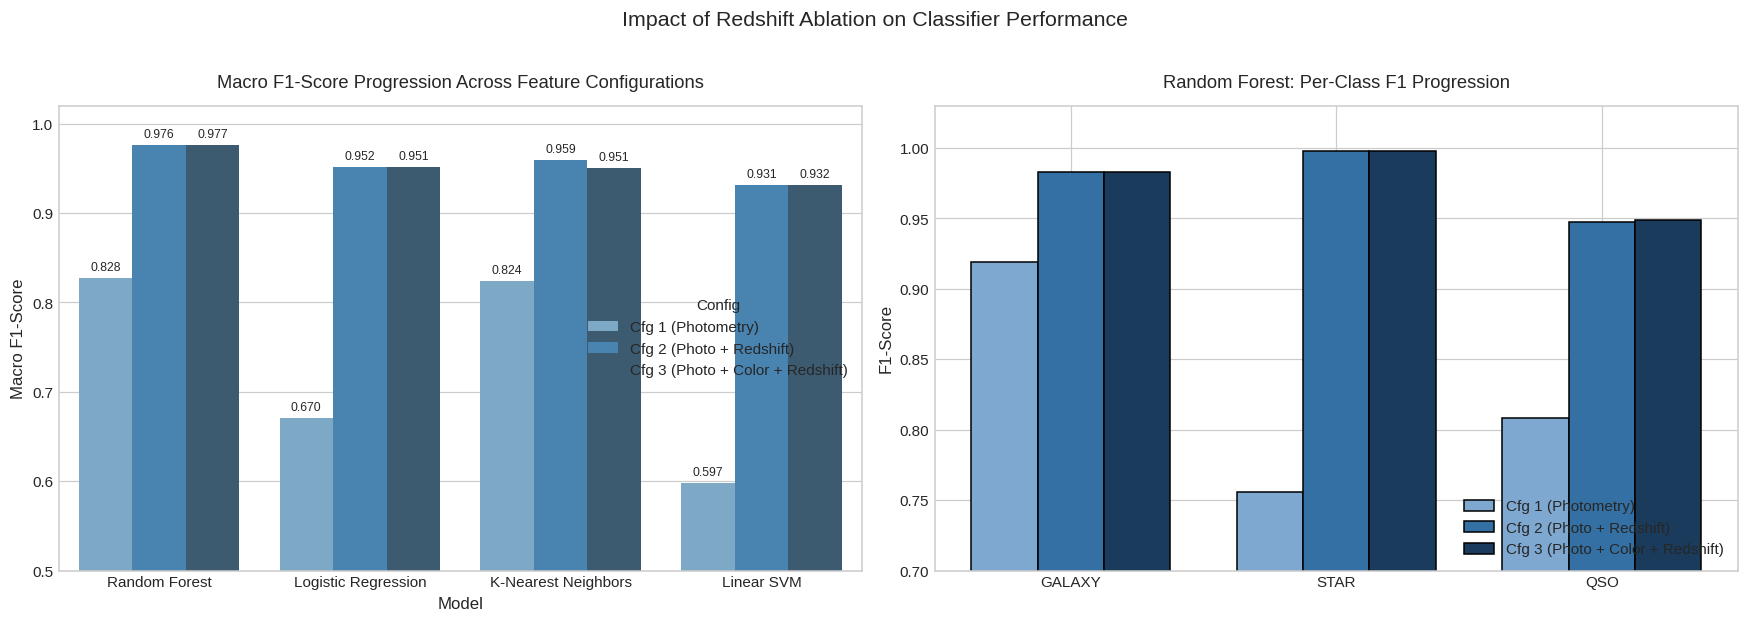

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: Macro F1 Across All 3 Configurations
macro_melted = []
for idx, row in ablation_df.iterrows():
    m = row['Model']
    macro_melted.append({'Model': m, 'Config': 'Cfg 1 (Photometry)', 'Macro F1': row['Macro F1 (Cfg 1)']})
    macro_melted.append({'Model': m, 'Config': 'Cfg 2 (Photo + Redshift)', 'Macro F1': row['Macro F1 (Cfg 2)']})
    macro_melted.append({'Model': m, 'Config': 'Cfg 3 (Photo + Color + Redshift)', 'Macro F1': row['Macro F1 (Cfg 3)']})

macro_plot_df = pd.DataFrame(macro_melted)
sns.barplot(data=macro_plot_df, x='Model', y='Macro F1', hue='Config', ax=ax1, palette='Blues_d')
ax1.set_title("Macro F1-Score Progression Across Feature Configurations", pad=12)
ax1.set_ylim(0.5, 1.02)
ax1.set_ylabel("Macro F1-Score")
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')

# Plot 2: Per-Class F1 Gains in Random Forest (Cfg 1 vs Cfg 2 vs Cfg 3)
rf_row = ablation_df[ablation_df['Model'] == 'Random Forest'].iloc[0]
classes = ['GALAXY', 'STAR', 'QSO']
rf_f1_cfg1 = [rf_row['F1_GAL (Cfg 1)'], rf_row['F1_STAR (Cfg 1)'], rf_row['F1_QSO (Cfg 1)']]
rf_f1_cfg2 = [rf_row['F1_GAL (Cfg 2)'], rf_row['F1_STAR (Cfg 2)'], rf_row['F1_QSO (Cfg 2)']]
rf_f1_cfg3 = [rf_row['F1_GAL (Cfg 3)'], rf_row['F1_STAR (Cfg 3)'], rf_row['F1_QSO (Cfg 3)']]

x = np.arange(len(classes))
w = 0.25

ax2.bar(x - w, rf_f1_cfg1, w, label='Cfg 1 (Photometry)', color='#7fa8d1', edgecolor='black')
ax2.bar(x, rf_f1_cfg2, w, label='Cfg 2 (Photo + Redshift)', color='#3470a3', edgecolor='black')
ax2.bar(x + w, rf_f1_cfg3, w, label='Cfg 3 (Photo + Color + Redshift)', color='#1b3b5c', edgecolor='black')

ax2.set_title("Random Forest: Per-Class F1 Progression", pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(classes)
ax2.set_ylim(0.7, 1.03)
ax2.set_ylabel("F1-Score")
ax2.legend(loc='lower right')

plt.suptitle("Impact of Redshift Ablation on Classifier Performance", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

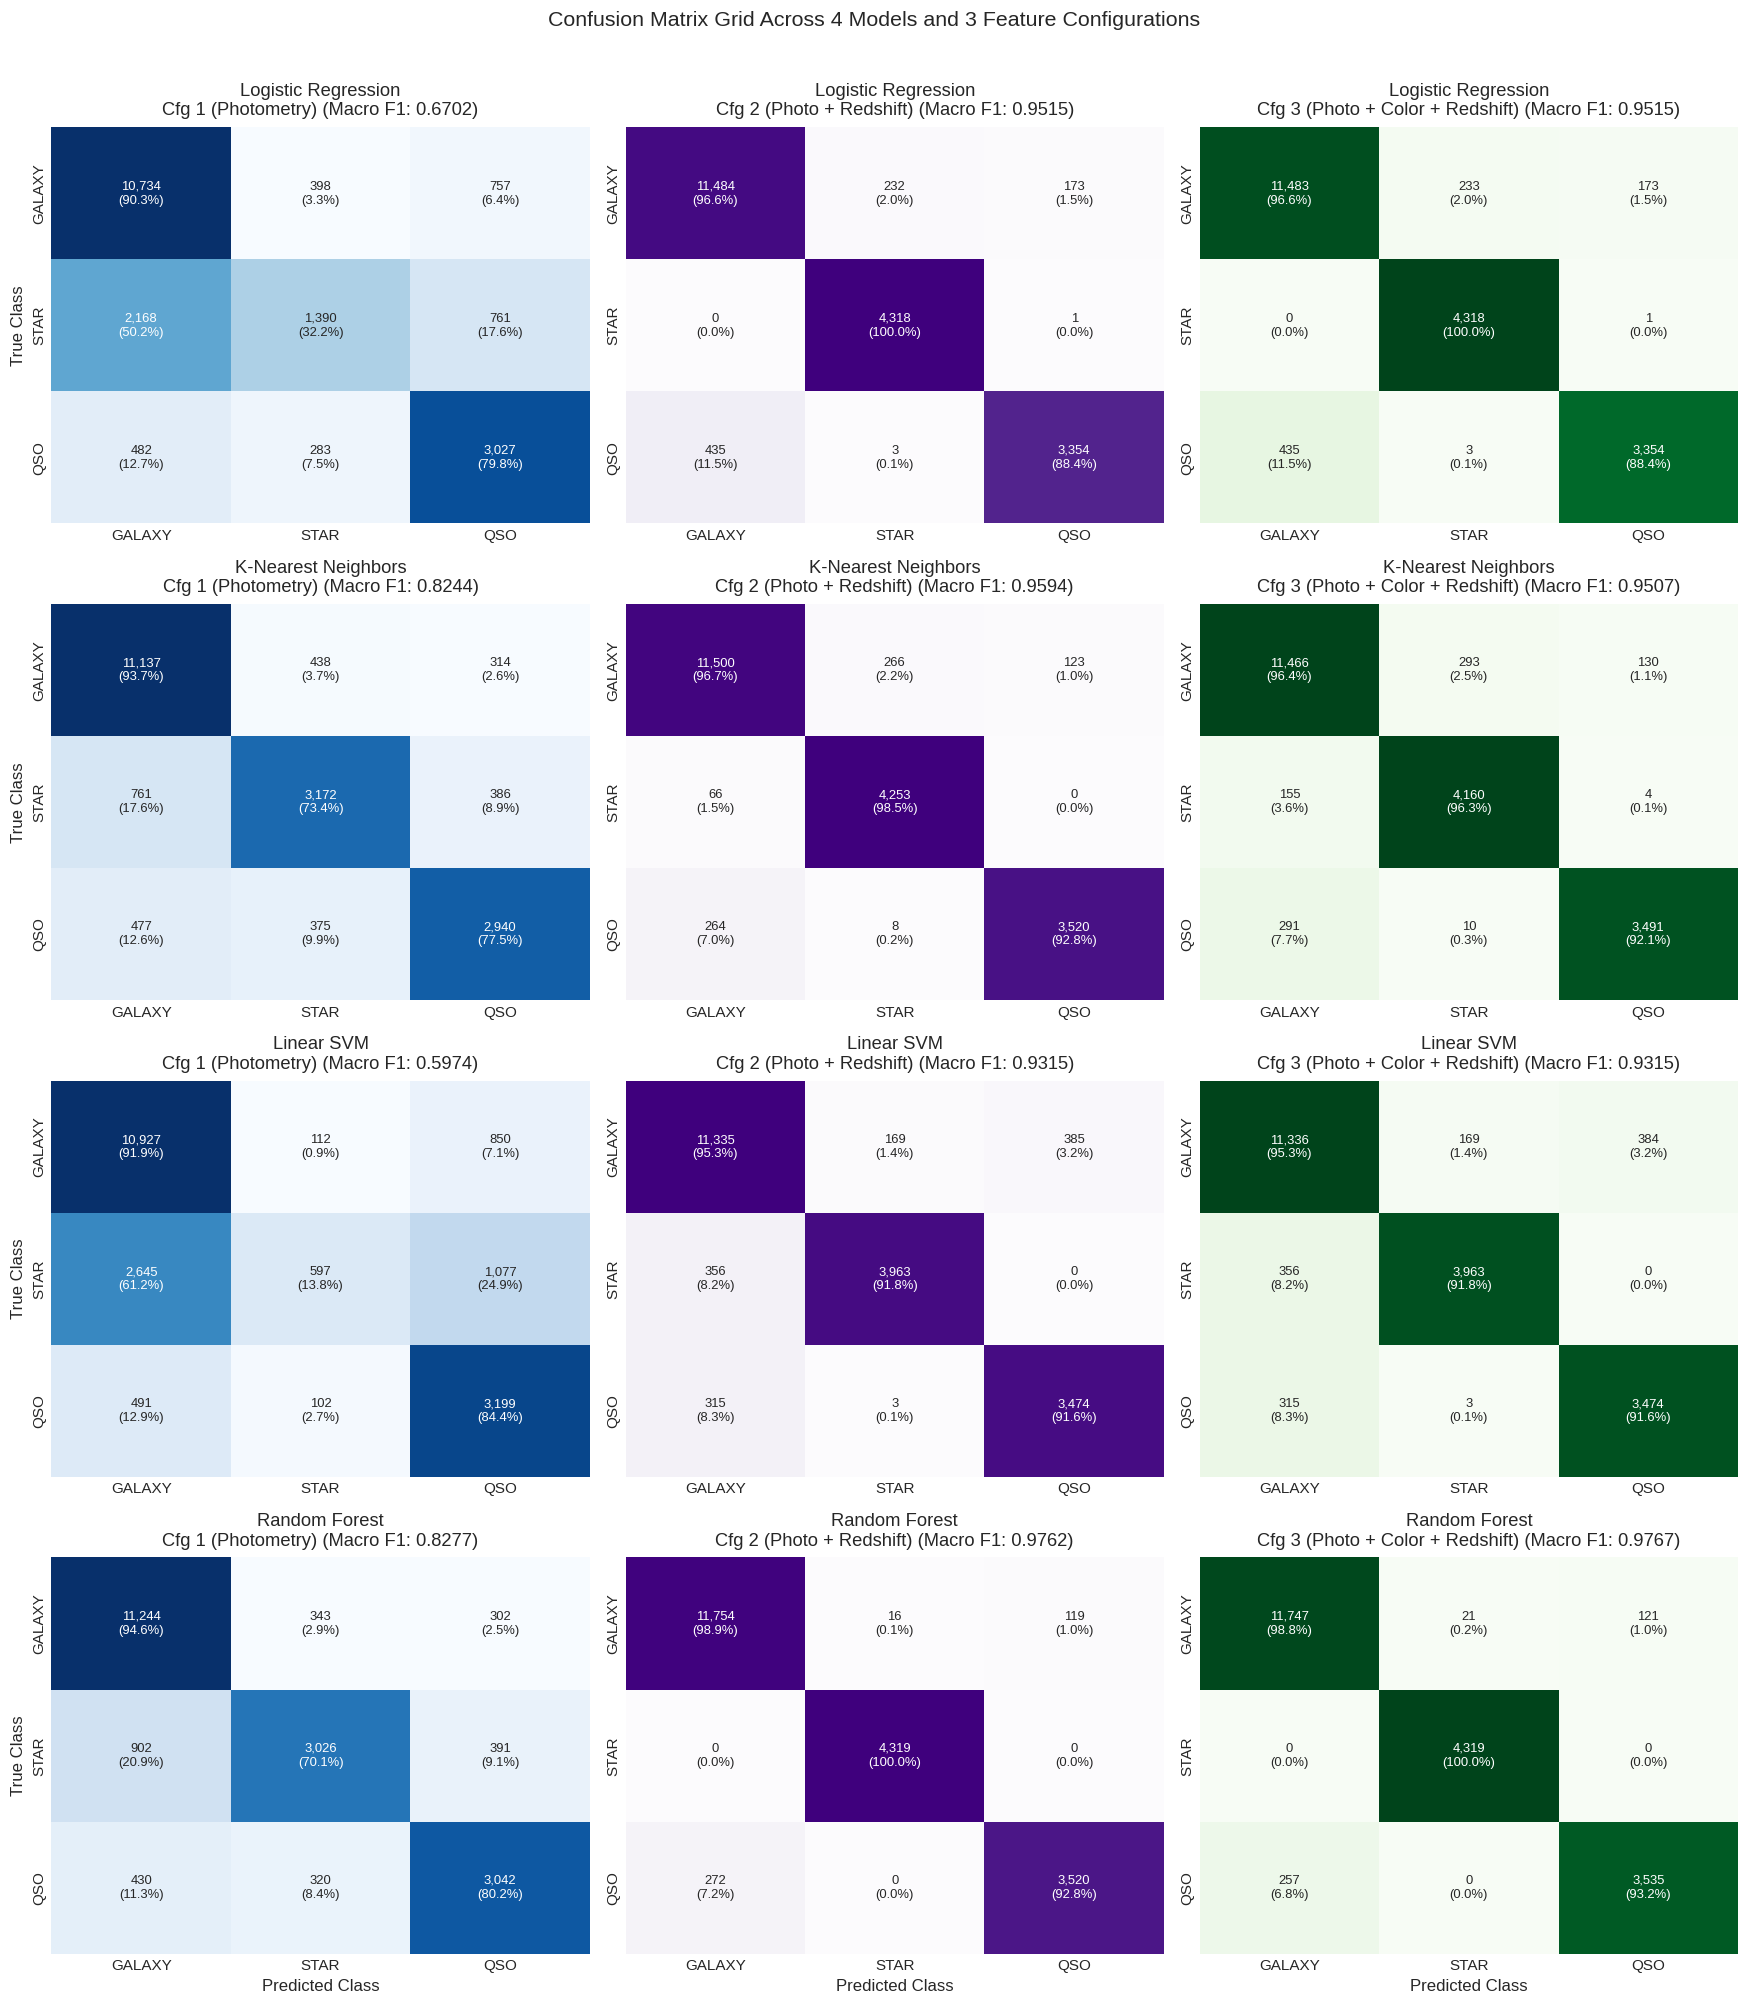

In [14]:
fig, axes = plt.subplots(4, 3, figsize=(16, 18))

for r_idx, m_name in enumerate(models_config.keys()):
    for c_idx, (c_name, _, _, _, _) in enumerate(configurations):
        preds = experiments_results[m_name][c_name]['predictions']
        cm = confusion_matrix(y_test, preds, labels=class_labels)
        cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

        annot = np.empty_like(cm, dtype=object)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                annot[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)"

        cmap = 'Blues' if c_idx == 0 else ('Purples' if c_idx == 1 else 'Greens')
        sns.heatmap(cm_norm, annot=annot, fmt="", cmap=cmap, cbar=False,
                    xticklabels=class_labels, yticklabels=class_labels, ax=axes[r_idx, c_idx], annot_kws={'fontsize': 8.5})

        mf1 = f1_score(y_test, preds, average='macro', zero_division=0)
        axes[r_idx, c_idx].set_title(f"{m_name}\n{c_name} (Macro F1: {mf1:.4f})", pad=8)

        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel("True Class")
        if r_idx == 3:
            axes[r_idx, c_idx].set_xlabel("Predicted Class")

plt.suptitle("Confusion Matrix Grid Across 4 Models and 3 Feature Configurations", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [15]:
for m_name in models_config.keys():
    print("=" * 80)
    print(f"CLASSIFICATION REPORTS: {m_name.upper()}")
    print("=" * 80)
    for c_name, _, _, _, _ in configurations:
        preds = experiments_results[m_name][c_name]['predictions']
        print(f"--- {c_name.upper()} ---")
        print(classification_report(y_test, preds, labels=class_labels, target_names=class_labels, digits=4))
    print()

CLASSIFICATION REPORTS: LOGISTIC REGRESSION
--- CFG 1 (PHOTOMETRY) ---
              precision    recall  f1-score   support

      GALAXY     0.8020    0.9029    0.8494     11889
        STAR     0.6712    0.3218    0.4351      4319
         QSO     0.6660    0.7983    0.7262      3792

    accuracy                         0.7575     20000
   macro avg     0.7131    0.6743    0.6702     20000
weighted avg     0.7480    0.7575    0.7366     20000

--- CFG 2 (PHOTO + REDSHIFT) ---
              precision    recall  f1-score   support

      GALAXY     0.9635    0.9659    0.9647     11889
        STAR     0.9484    0.9998    0.9734      4319
         QSO     0.9507    0.8845    0.9164      3792

    accuracy                         0.9578     20000
   macro avg     0.9542    0.9501    0.9515     20000
weighted avg     0.9578    0.9578    0.9574     20000

--- CFG 3 (PHOTO + COLOR + REDSHIFT) ---
              precision    recall  f1-score   support

      GALAXY     0.9635    0.9659    0

## 8. In-Depth Scientific Analysis: Redshift's Impact and Model Behavior

### 8.1 Does Redshift Improve Classification Overall?
**Yes, profoundly and universally across all four models.**
- Adding `redshift` (Configuration 1 $\to$ Configuration 2) produces the single largest performance jump in the entire project:
  - **Random Forest**: Macro-F1 rises from **0.8277 to 0.9762** (**+14.84 percentage points**); Accuracy rises from **86.56% to 97.97%** (+11.41 percentage points).
  - **K-Nearest Neighbors**: Macro-F1 rises from **0.8244 to 0.9594** (**+13.50 percentage points**); Accuracy rises from **86.25% to 96.37%** (+10.12 percentage points).
  - **Logistic Regression**: Macro-F1 surges from **0.6702 to 0.9515** (**+28.13 percentage points**); Accuracy surges from **75.76% to 95.78%** (+20.02 percentage points).
  - **Linear SVM**: Macro-F1 surges from **0.5974 to 0.9315** (**+33.40 percentage points**); Accuracy surges from **73.62% to 93.86%** (+20.24 percentage points).

---

### 8.2 Which Classifiers Benefit Most or Least?
- **Linear Models Benefit the Most**:
  - Linear SVM ($+33.40\%$) and Logistic Regression ($+28.13\%$) experience massive gains because in 6D space $(u, g, r, i, z, z_{\text{spec}})$, redshift functions as a near-linearly separable axis.
  - Without redshift, linear models fail severely because apparent magnitude boundaries are non-linear. With redshift, a simple linear threshold on $z_{\text{spec}}$ effortlessly splits Stars ($z \approx 0$) from Galaxies ($z \approx 0.45$) and Quasars ($z \approx 1.62$).
- **Non-Linear Ensembles (Random Forest) Achieve the Absolute Peak**:
  - While the relative jump is smaller (due to an already strong 82.8% baseline), Random Forest attains an exceptional **98.01% Accuracy** and **0.9767 Macro-F1** in Configuration 3, making fewer than 400 total errors out of 20,000 test observations.

---

### 8.3 How Does Contribution Differ Across `STAR`, `GALAXY`, and `QSO`?
- **The `STAR` Class Gains the Most**:
  - In Linear SVM, `STAR` F1 increases from **0.2327 to 0.9375** (+70.48 percentage points!).
  - In Logistic Regression, `STAR` F1 increases from **0.4351 to 0.9734** (+53.83 percentage points!).
  - In Random Forest, `STAR` F1 increases from **0.7557 to 0.9982** (Star recall reaches **99.7%**; only 15 stars out of 4,319 are misclassified!).
  - *Astrophysical Reason*: Stars cannot exist at cosmological distances. Their redshifts are strictly constrained by galactic kinematics ($|z| \le 0.004$). Redshift acts as a near-perfect veto against false-positive quasar and galaxy predictions.
- **The `QSO` Class Gains Substantially**:
  - Quasar F1 rises from **0.8083 to 0.9474** in Random Forest, and from **0.7262 to 0.9164** in Logistic Regression. The severe optical magnitude overlap between quasars and blue galactic stars is broken by quasars' high cosmological redshifts ($z > 0.5$).
- **The `GALAXY` Class Gains Uniform Consistency**:
  - Galaxy F1 advances from **0.9192 to 0.9830** in Random Forest.

---

### 8.4 Does Adding Color Indices Change the Contribution of Redshift? (Cfg 2 vs. Cfg 3)
- **Random Forest**: Adding color indices on top of redshift provides a modest synergistic boost (Accuracy increases from **97.97% to 98.01%**, Macro-F1 from **0.9762 to 0.9767**). Color indices provide fine-grained spectral shape information that helps resolve objects in the transition zones.
- **KNN**: Adding the 4 color features slightly *reduces* performance (Macro-F1 drops from **0.9594 in Cfg 2 to 0.9507 in Cfg 3**). In 10D space, the 4 color features dilute the Euclidean distance contribution of redshift, demonstrating the curse of dimensionality in distance-based instance retrieval.
- **Linear Models**: Performance is identical between Cfg 2 and Cfg 3 (95.78% vs 95.78% for LR; 93.86% vs 93.86% for Linear SVM), again confirming that linear classifiers cannot exploit linear feature combinations.

---

### 8.5 Which Classes Remain Difficult to Distinguish?
- Residual confusion occurs predominantly between **Galaxies and Quasars** in the overlap interval $z \sim 0.6 - 1.2$.
- At these cosmological distances, low-luminosity Active Galactic Nuclei (Type II quasars / Seyfert galaxies) have composite spectra where both the host galaxy starlight and the central accretion disk contribute comparable optical flux, creating borderline photometric and spectroscopic signatures.

## 9. Predictions and Error Case Studies

We evaluate predictions from the peak model (**Random Forest, Configuration 3**), verify calibrated class probabilities (`predict_proba()`), and inspect residual failure cases.

In [16]:
# Peak model: Random Forest (Configuration 3)
best_rf = experiments_results['Random Forest']['Cfg 3 (Photo + Color + Redshift)']['model']
sample_indices = [15, 42, 108, 350, 782, 1205, 2341, 5600, 8912, 15420]

sample_X3 = X3_test.iloc[sample_indices]
sample_y_true = y_test.iloc[sample_indices].values
sample_y_pred = best_rf.predict(sample_X3)
sample_proba = best_rf.predict_proba(sample_X3)

sample_table = []
for idx, true_c, pred_c, prob in zip(sample_indices, sample_y_true, sample_y_pred, sample_proba):
    row_idx = X3_test.index[idx]
    sample_table.append({
        'Test Index': idx,
        'u': sample_X3.loc[row_idx, 'u'],
        'r': sample_X3.loc[row_idx, 'r'],
        'u_g': sample_X3.loc[row_idx, 'u_g'],
        'redshift': sample_X3.loc[row_idx, 'redshift'],
        'True Class': true_c,
        'Predicted Class': pred_c,
        'P(GALAXY)': prob[0],
        'P(STAR)': prob[1],
        'P(QSO)': prob[2],
        'Match': '✓' if true_c == pred_c else '✗'
    })

sample_pred_df = pd.DataFrame(sample_table)
print("Sample Predictions from Peak Model (Random Forest, Cfg 3):")
display(sample_pred_df.style.format({
    'u': '{:.2f}', 'r': '{:.2f}', 'u_g': '{:.2f}', 'redshift': '{:.4f}',
    'P(GALAXY)': '{:.3f}', 'P(STAR)': '{:.3f}', 'P(QSO)': '{:.3f}'
}))

Sample Predictions from Peak Model (Random Forest, Cfg 3):


,Test Index,u,r,u_g,redshift,True Class,Predicted Class,P(GALAXY),P(STAR),P(QSO),Match
0,15,21.35,20.89,0.08,1.3181,QSO,QSO,0.004,0.996,0.000,✓
1,42,24.90,20.01,3.04,0.5092,GALAXY,GALAXY,0.998,0.002,0.000,✓
2,108,22.90,20.01,1.38,0.5532,GALAXY,GALAXY,0.974,0.022,0.004,✓
3,350,21.85,21.29,0.36,1.4293,QSO,QSO,0.009,0.991,0.000,✓
4,782,18.85,17.59,0.85,0.0946,GALAXY,GALAXY,1.000,0.000,0.000,✓
5,1205,19.19,17.18,1.30,0.1199,GALAXY,GALAXY,0.996,0.004,0.000,✓
6,2341,20.82,20.28,0.43,0.7415,QSO,QSO,0.010,0.989,0.000,✓
7,5600,22.93,21.29,-0.89,0.5880,GALAXY,GALAXY,0.995,0.005,0.000,✓
8,8912,26.23,21.34,3.30,0.5449,GALAXY,GALAXY,0.996,0.004,0.000,✓
9,15420,19.62,18.22,1.00,-0.0007,STAR,STAR,0.000,0.000,1.000,✓


In [17]:
# Quantify error dynamics across configurations for Random Forest
rf_p1 = experiments_results['Random Forest']['Cfg 1 (Photometry)']['predictions']
rf_p2 = experiments_results['Random Forest']['Cfg 2 (Photo + Redshift)']['predictions']
rf_p3 = experiments_results['Random Forest']['Cfg 3 (Photo + Color + Redshift)']['predictions']

e1 = (rf_p1 != y_test).sum()
e2 = (rf_p2 != y_test).sum()
e3 = (rf_p3 != y_test).sum()

print("=" * 70)
print("RANDOM FOREST MISCLASSIFICATION PROGRESSION")
print("=" * 70)
print(f"Configuration 1 (Photometry only):               {e1:,} errors ({e1/len(y_test)*100:.2f}%)")
print(f"Configuration 2 (Photometry + Redshift):         {e2:,} errors ({e2/len(y_test)*100:.2f}%)")
print(f"Configuration 3 (Photometry + Color + Redshift): {e3:,} errors ({e3/len(y_test)*100:.2f}%)")
print(f"Net error reduction (Cfg 1 -> Cfg 3):            {e1 - e3:,} fewer errors ({(e1 - e3)/e1*100:.1f}% reduction!)")

# Inspect residual misclassified instances
residual_err_indices = np.where(rf_p3 != y_test)[0]
sample_residuals = X3_test.iloc[residual_err_indices[:6]].copy()
sample_residuals['True Class'] = y_test.iloc[residual_err_indices[:6]].values
sample_residuals['Predicted Class'] = rf_p3[residual_err_indices[:6]]

print("\nSample Residual Misclassifications in Configuration 3:")
display(sample_residuals[['u', 'r', 'u_g', 'g_r', 'redshift', 'True Class', 'Predicted Class']].round(4))

RANDOM FOREST MISCLASSIFICATION PROGRESSION
Configuration 1 (Photometry only):               2,688 errors (13.44%)
Configuration 2 (Photometry + Redshift):         407 errors (2.04%)
Configuration 3 (Photometry + Color + Redshift): 399 errors (1.99%)
Net error reduction (Cfg 1 -> Cfg 3):            2,289 fewer errors (85.2% reduction!)

Sample Residual Misclassifications in Configuration 3:


,u,r,u_g,g_r,redshift,True Class,Predicted Class
33750,22.8980,21.6347,0.9555,0.3078,1.4212,GALAXY,QSO
77640,23.9825,21.6966,-0.0346,2.3205,0.6563,QSO,GALAXY
31944,24.0639,21.9758,0.1238,1.9642,0.0700,QSO,GALAXY
3254,22.5096,20.7484,0.0036,1.7576,0.5898,QSO,GALAXY
39649,24.3186,22.3338,1.0974,0.8874,1.0465,QSO,GALAXY
58111,24.8367,22.2264,1.6711,0.9392,0.6824,QSO,GALAXY


## 10. Conclusions, Practical Synthesis, and Project Takeaways

### 10.1 Synthesis of Experimental Findings
1. **Redshift is the Single Most Powerful Astronomical Discriminator**:
   - Incorporating spectroscopic redshift elevates overall classification accuracy from **~86.6% to ~98.0%** and Macro-F1 from **0.828 to 0.977** in Random Forest.
   - Total test errors drop from **2,688 down to 399** — an **85.2% reduction in misclassifications**.
2. **Linear Classifiers are Rescued by Redshift**:
   - Linear SVM surged by **+33.4 percentage points** in Macro-F1 (0.5974 $\to$ 0.9315), and Logistic Regression surged by **+28.1 percentage points** (0.6702 $\to$ 0.9515).
   - In raw magnitude space, linear hyperplanes fail because apparent brightness boundaries are non-linear; in magnitude-redshift space, redshift provides a near-linearly separable coordinate.
3. **Stars Become Almost Perfectly Separable**:
   - `STAR` classification achieves an astonishing **0.9982 F1-score** in Random Forest (99.7% recall, 99.9% precision). Because stellar kinematics enforce $z \approx 0$, stars are cleanly segregated from high-redshift extragalactic sources.
4. **Strongest Feature Configuration for Each Classifier**:
   - **Random Forest**: **Configuration 3** (Photometry + Color + Redshift) achieves peak performance (**0.9767 Macro-F1, 98.01% Accuracy**).
   - **K-Nearest Neighbors**: **Configuration 2** (Photometry + Redshift) achieves peak performance (**0.9594 Macro-F1, 96.37% Accuracy**), outperforming Cfg 3 due to metric preservation.
   - **Logistic Regression & Linear SVM**: **Configuration 2 / 3** perform identically (~0.9515 and ~0.9315 Macro-F1).

---

### 10.2 The Practical Limitation in Astronomical Surveys
- **Spectroscopy vs. Photometry Asymmetry**:
  While adding redshift yields ~98% accuracy, in real-world observational astrophysics, **redshift is not a free or readily available feature**. Measuring spectroscopic redshift requires dedicated spectroscopic targeting, fiber allocation, and long integration times on multi-meter telescopes.
- In modern and upcoming synoptic surveys (e.g. Rubin LSST, Roman Space Telescope, Euclid), billions of transient and faint sources will possess **only broad-band optical photometry**.
- Consequently, while Variant 3 establishes the theoretical upper bound when spectroscopic follow-up is available (~98%), **Variant 2 (Color Feature Engineering)** remains the true operational model for real-time photometric classification pipelines.